# Task 4: Classification with Logistic Regression

Build a binary classification model using Logistic Regression to predict breast cancer diagnosis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data.csv")

df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [2]:
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (569, 33)

Data types:
id                           int64
diagnosis                      str
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst

In [3]:
print("\nDiagnosis distribution:")
print(df["diagnosis"].value_counts())


Diagnosis distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64


In [4]:
df = df.drop(columns=["id", "Unnamed: 32"])

print("Dataset shape after removing unnecessary columns:", df.shape)
print("\nRemaining missing values:", df.isnull().sum().sum())
print("\nRemaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing unnecessary columns: (569, 31)

Remaining missing values: 0

Remaining duplicate rows: 0


In [5]:
df["diagnosis"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

print(df["diagnosis"].value_counts())
print("\nTarget data type:", df["diagnosis"].dtype)

diagnosis
0    357
1    212
Name: count, dtype: int64

Target data type: int64


In [6]:
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (569, 30)
Target shape: (569,)

Target distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

X_train shape: (455, 30)
X_test shape: (114, 30)
y_train shape: (455,)
y_test shape: (114,)

Training target distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Testing target distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training features standardized.")
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

Training features standardized.
X_train_scaled shape: (455, 30)
X_test_scaled shape: (114, 30)


## Logistic Regression Model

A Logistic Regression model is trained on the standardized training features to classify breast cancer cases as benign or malignant.

In [9]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(random_state=42)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [10]:
y_pred = logistic_model.predict(X_test_scaled)
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("First 10 predicted classes:")
print(y_pred[:10])

print("\nFirst 10 predicted probabilities:")
print(y_prob[:10])

First 10 predicted classes:
[0 1 0 1 1 0 1 0 0 0]

First 10 predicted probabilities:
[3.64568116e-04 9.99999989e-01 4.25679471e-02 5.76187322e-01
 5.09155489e-01 6.16001620e-04 7.61534086e-01 1.01217174e-03
 5.68725516e-04 1.07675795e-02]


In [11]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Precision
precision = precision_score(y_test, y_pred)
print("\nPrecision:", precision)

# Recall
recall = recall_score(y_test, y_pred)
print("Recall:", recall)

# ROC-AUC
roc_auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC:", roc_auc)

Confusion Matrix:
[[71  1]
 [ 3 39]]

Precision: 0.975
Recall: 0.9285714285714286
ROC-AUC: 0.996031746031746


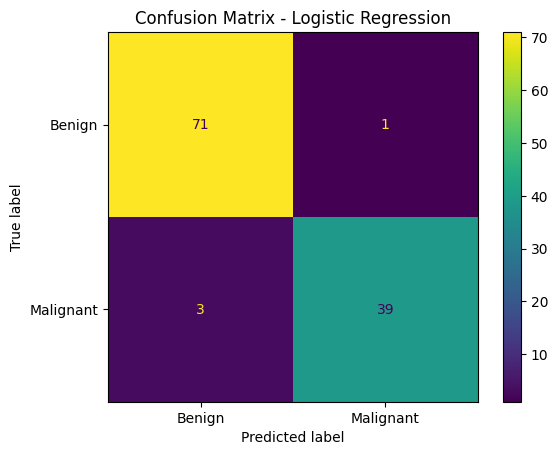

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
).plot()

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

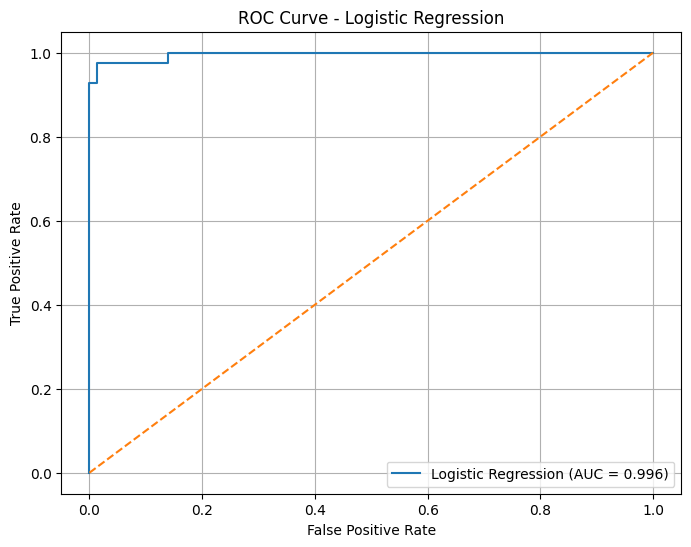

In [13]:
from sklearn.metrics import roc_curve

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid()
plt.show()

In [14]:
# Threshold tuning

thresholds_to_test = [0.3, 0.4, 0.5, 0.6, 0.7]

print("Threshold | Precision | Recall")
print("-" * 35)

for threshold in thresholds_to_test:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)

    print(f"{threshold:^9.1f} | {precision:^9.3f} | {recall:^6.3f}")

Threshold | Precision | Recall
-----------------------------------
   0.3    |   0.976   | 0.976 
   0.4    |   0.976   | 0.952 
   0.5    |   0.975   | 0.929 
   0.6    |   1.000   | 0.905 
   0.7    |   1.000   | 0.905 


In [15]:
# Final evaluation with tuned threshold = 0.3

tuned_threshold = 0.3

y_pred_tuned = (y_prob >= tuned_threshold).astype(int)

cm_tuned = confusion_matrix(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)

print("Tuned Threshold:", tuned_threshold)

print("\nConfusion Matrix:")
print(cm_tuned)

print("\nPrecision:", precision_tuned)
print("Recall:", recall_tuned)

Tuned Threshold: 0.3

Confusion Matrix:
[[71  1]
 [ 1 41]]

Precision: 0.9761904761904762
Recall: 0.9761904761904762


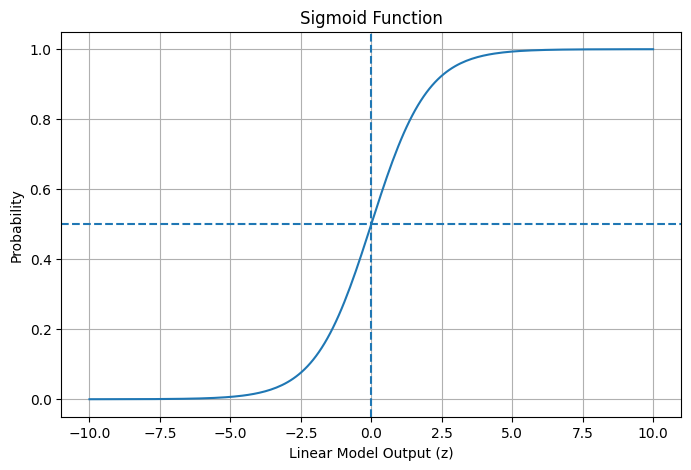

In [16]:
# Sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Values for plotting
z = np.linspace(-10, 10, 200)
probabilities = sigmoid(z)

# Plot sigmoid curve
plt.figure(figsize=(8, 5))
plt.plot(z, probabilities)

plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")

plt.xlabel("Linear Model Output (z)")
plt.ylabel("Probability")
plt.title("Sigmoid Function")
plt.grid()
plt.show()